# Beer Game: revised design and sample-size sweep

**Start in free review mode.** This notebook shows the completed study, revised prompts, independent-block design and spending plan. It can run a **four-call technical pilot**, not a significant hypothesis study. No new paid calls run by opening this notebook or using its default settings.

The completed sample tests pressure wording only. The new three-arm design restricts **reconsideration opportunities** (one response versus two), uses high effort throughout, and includes causal education. This is an AI resource analogue, not calibrated human decision-time pressure. Development self-checks are excluded from held-out results.

1. Run all cells unchanged to review.
2. Read the displayed budget, report and free self-check before spending.
3. For the optional technical pilot, set `RUN_API=True`, run all cells, enter the two keys in the hidden fields and click **Run four format checks**. Maximum new pilot spending is $1.50 and the SAME cumulative $5 guard applies. The exact bound is displayed first. Pilot responses are not independent treatment observations.
4. The progress bar and current-request timer stay here. Original prompts, responses and usage receipts are saved automatically. Rerunning resumes verified slots without rebilling.
5. Full games are blocked when the whole fixed sample lacks funding. Do not increase the old ledger cap, lower output allowances until JSON fails, or treat extra batched chains as independent replications.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/beergame_study").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from beergame_study import pivot_transport_v2 as api
from IPython.display import display, Markdown, Image
import pandas as pd

RUN_API = False
BLOCKS = 40  # prospective independent blocks/model; prefixes 10/20/40
CHAINS_PER_CLUSTER = 1  # more batched chains do not increase independent N
EXPERIMENT = ROOT / "experiments/13_weekly_state_api_20261021"
BUDGET_ROOT = ROOT / "experiments/12_pressure_framing_api_20261020"
ledger_before_review = api.sha(BUDGET_ROOT / "data/api_budget.json")
RUN = api.prepare(EXPERIMENT, BUDGET_ROOT, blocks=BLOCKS, chains_per_cluster=CHAINS_PER_CLUSTER)
PLAN = api.read(RUN / "plan.json")
COST = api.planning(RUN)
print("Prepared development run:", RUN.name)
print("Independent blocks/model:", BLOCKS, "| Arms: 3 | Weeks: 24")
print("Expected main+probe calls:", PLAN["expected_requests"])
display(pd.DataFrame([COST["budget"]]))
display(pd.DataFrame(COST["preflight"]))
print(f"All four pilot reservations: ${COST['preflight_reserve_usd']:.4f}; local cap $1.50.")
print(f"Full-sample conservative bound: ${COST['full_fixed_sample_reservation_bound_usd']:.2f}.")
print("Full study funded by remaining authorization:", COST["main_authorized_with_current_budget"])
display(pd.DataFrame(COST["scenarios"]))
assert api.sha(BUDGET_ROOT / "data/api_budget.json") == ledger_before_review

Prepared development run: pivot_v2_f8d6c96603807346
Independent blocks/model: 40 | Arms: 3 | Weeks: 24
Expected main+probe calls: 16000


,cap_usd,charged_or_reserved_usd,remaining_usd,attempts,ledger_sha256
0,5.0,1.179072,3.820928,115,81f75f9fb53f87f3ef979b11f086a7ac787c15c2cf6d9b...


,model,reserve_usd
0,gpt-6-luna,0.006272
1,gpt-6.1-sol,0.125457
2,gpt-6-astra,0.627287
3,claude-sonnet-5-5,0.151040


All four pilot reservations: $0.9101; local cap $1.50.
Full-sample conservative bound: $4605.14.
Full study funded by remaining authorization: False


,independent_blocks,calls,output_allowance,assumed_input_tokens_per_call,no_cache_consumed_cap_scenario_usd
0,10,4000,2048,2000,178.634
1,10,4000,4096,2000,323.018
2,10,4000,8192,2000,611.786
3,20,8000,2048,2000,357.268
4,20,8000,4096,2000,646.036
5,20,8000,8192,2000,1223.572
6,40,16000,2048,2000,714.536
7,40,16000,4096,2000,1292.072
8,40,16000,8192,2000,2447.144


## Review the actual results first

The figures below use the closed weekly-state run. The 10-versus-20-chain plot is **descriptive** because those chains were jointly generated. The separate 10/20/40-independent-block power plot uses hypothetical effect sizes, not invented observations. See `reports/review_20261025/REPORT.md` for the audit and interpretation.


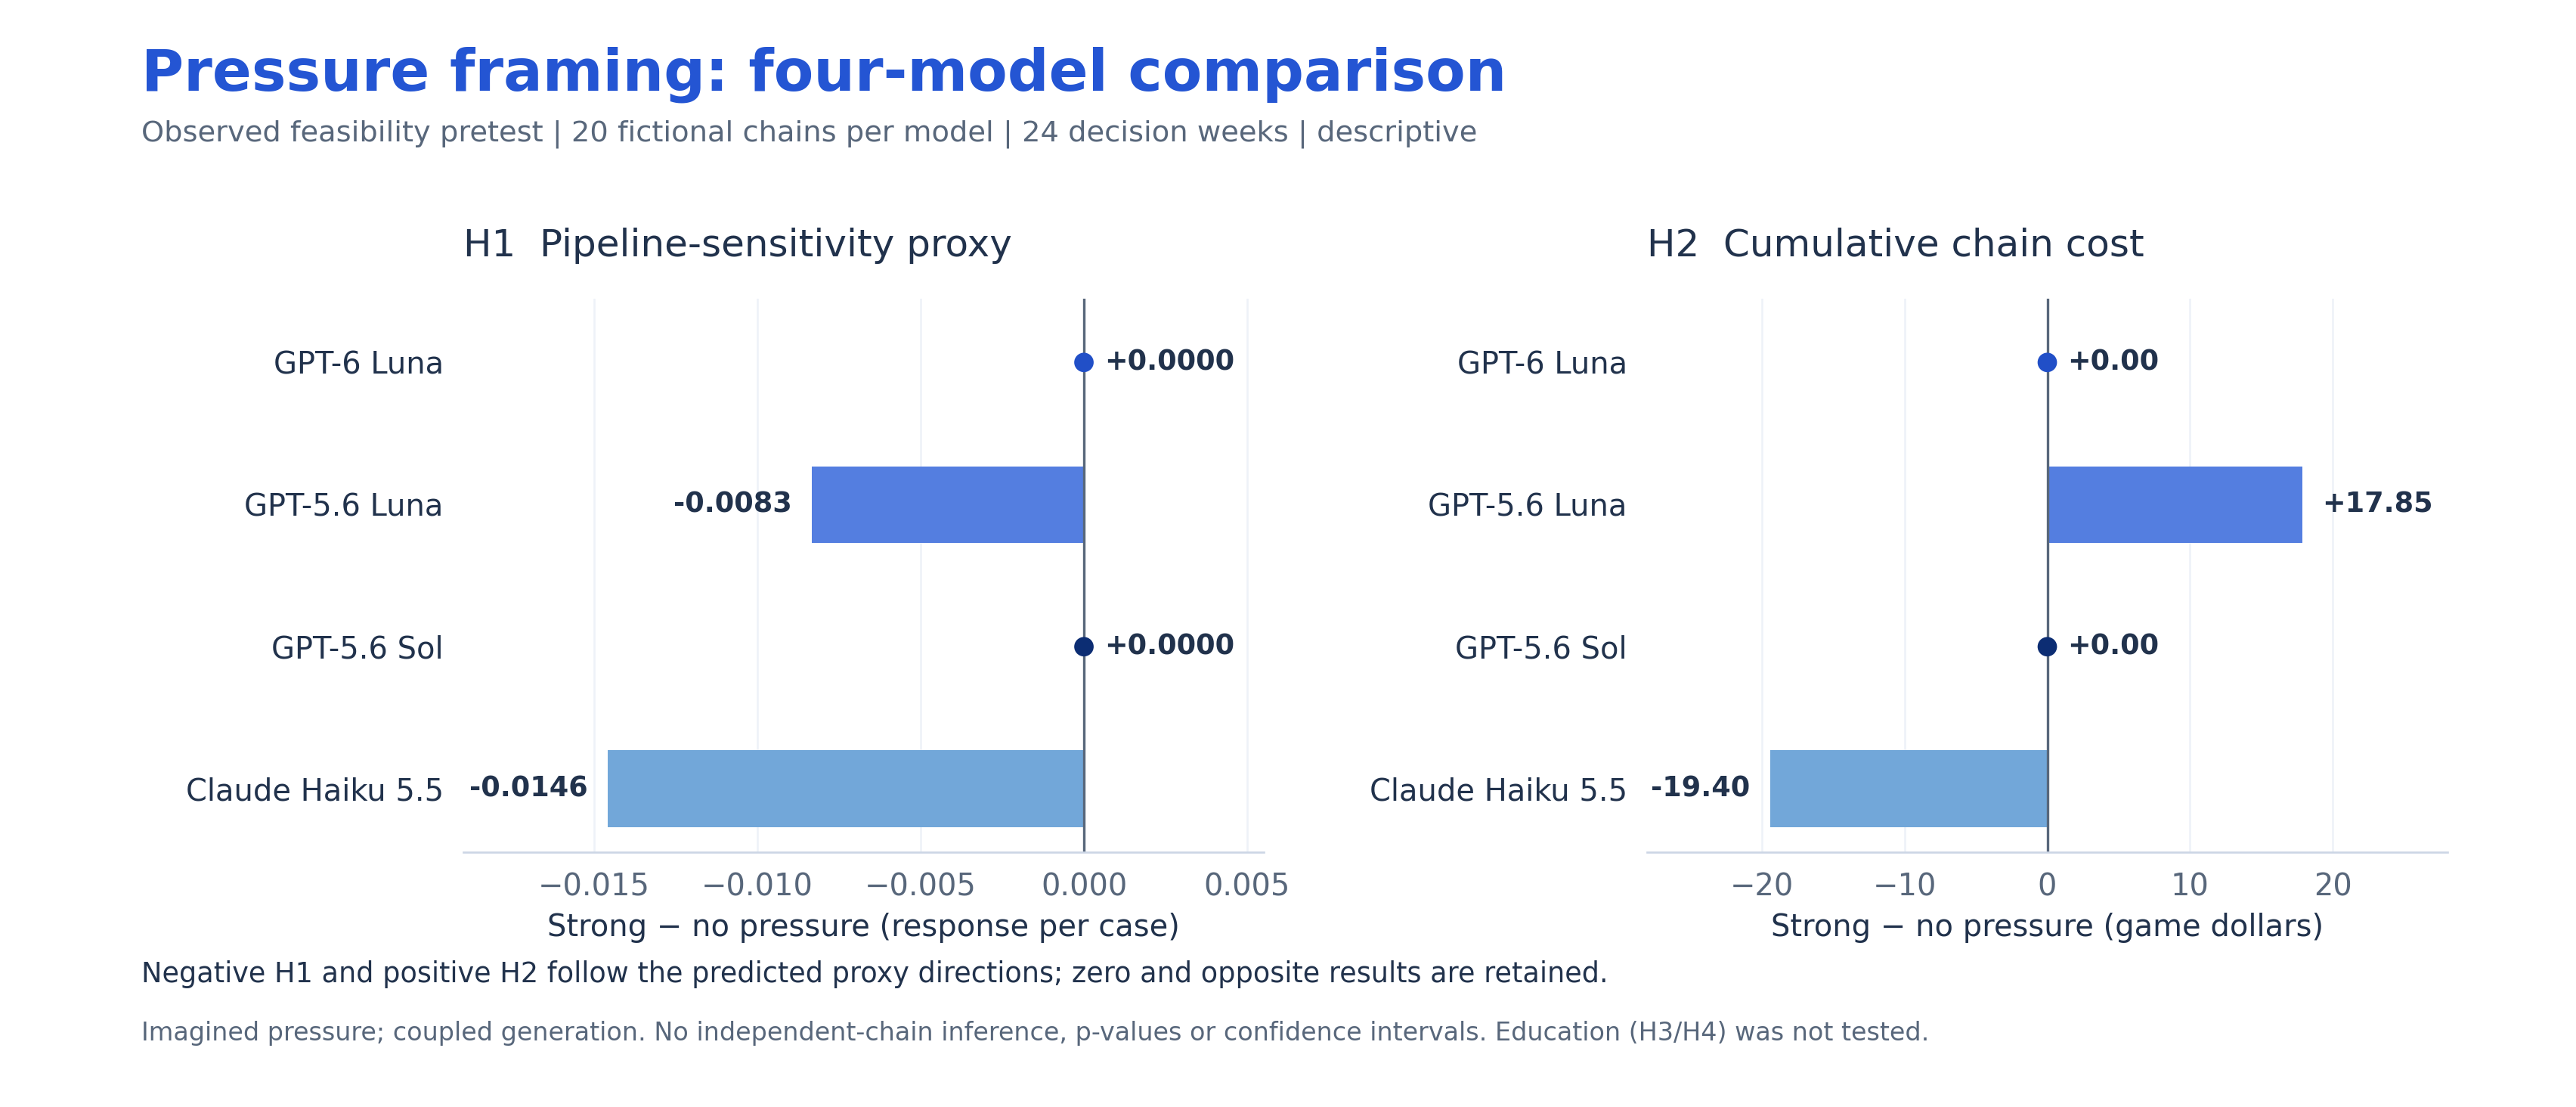

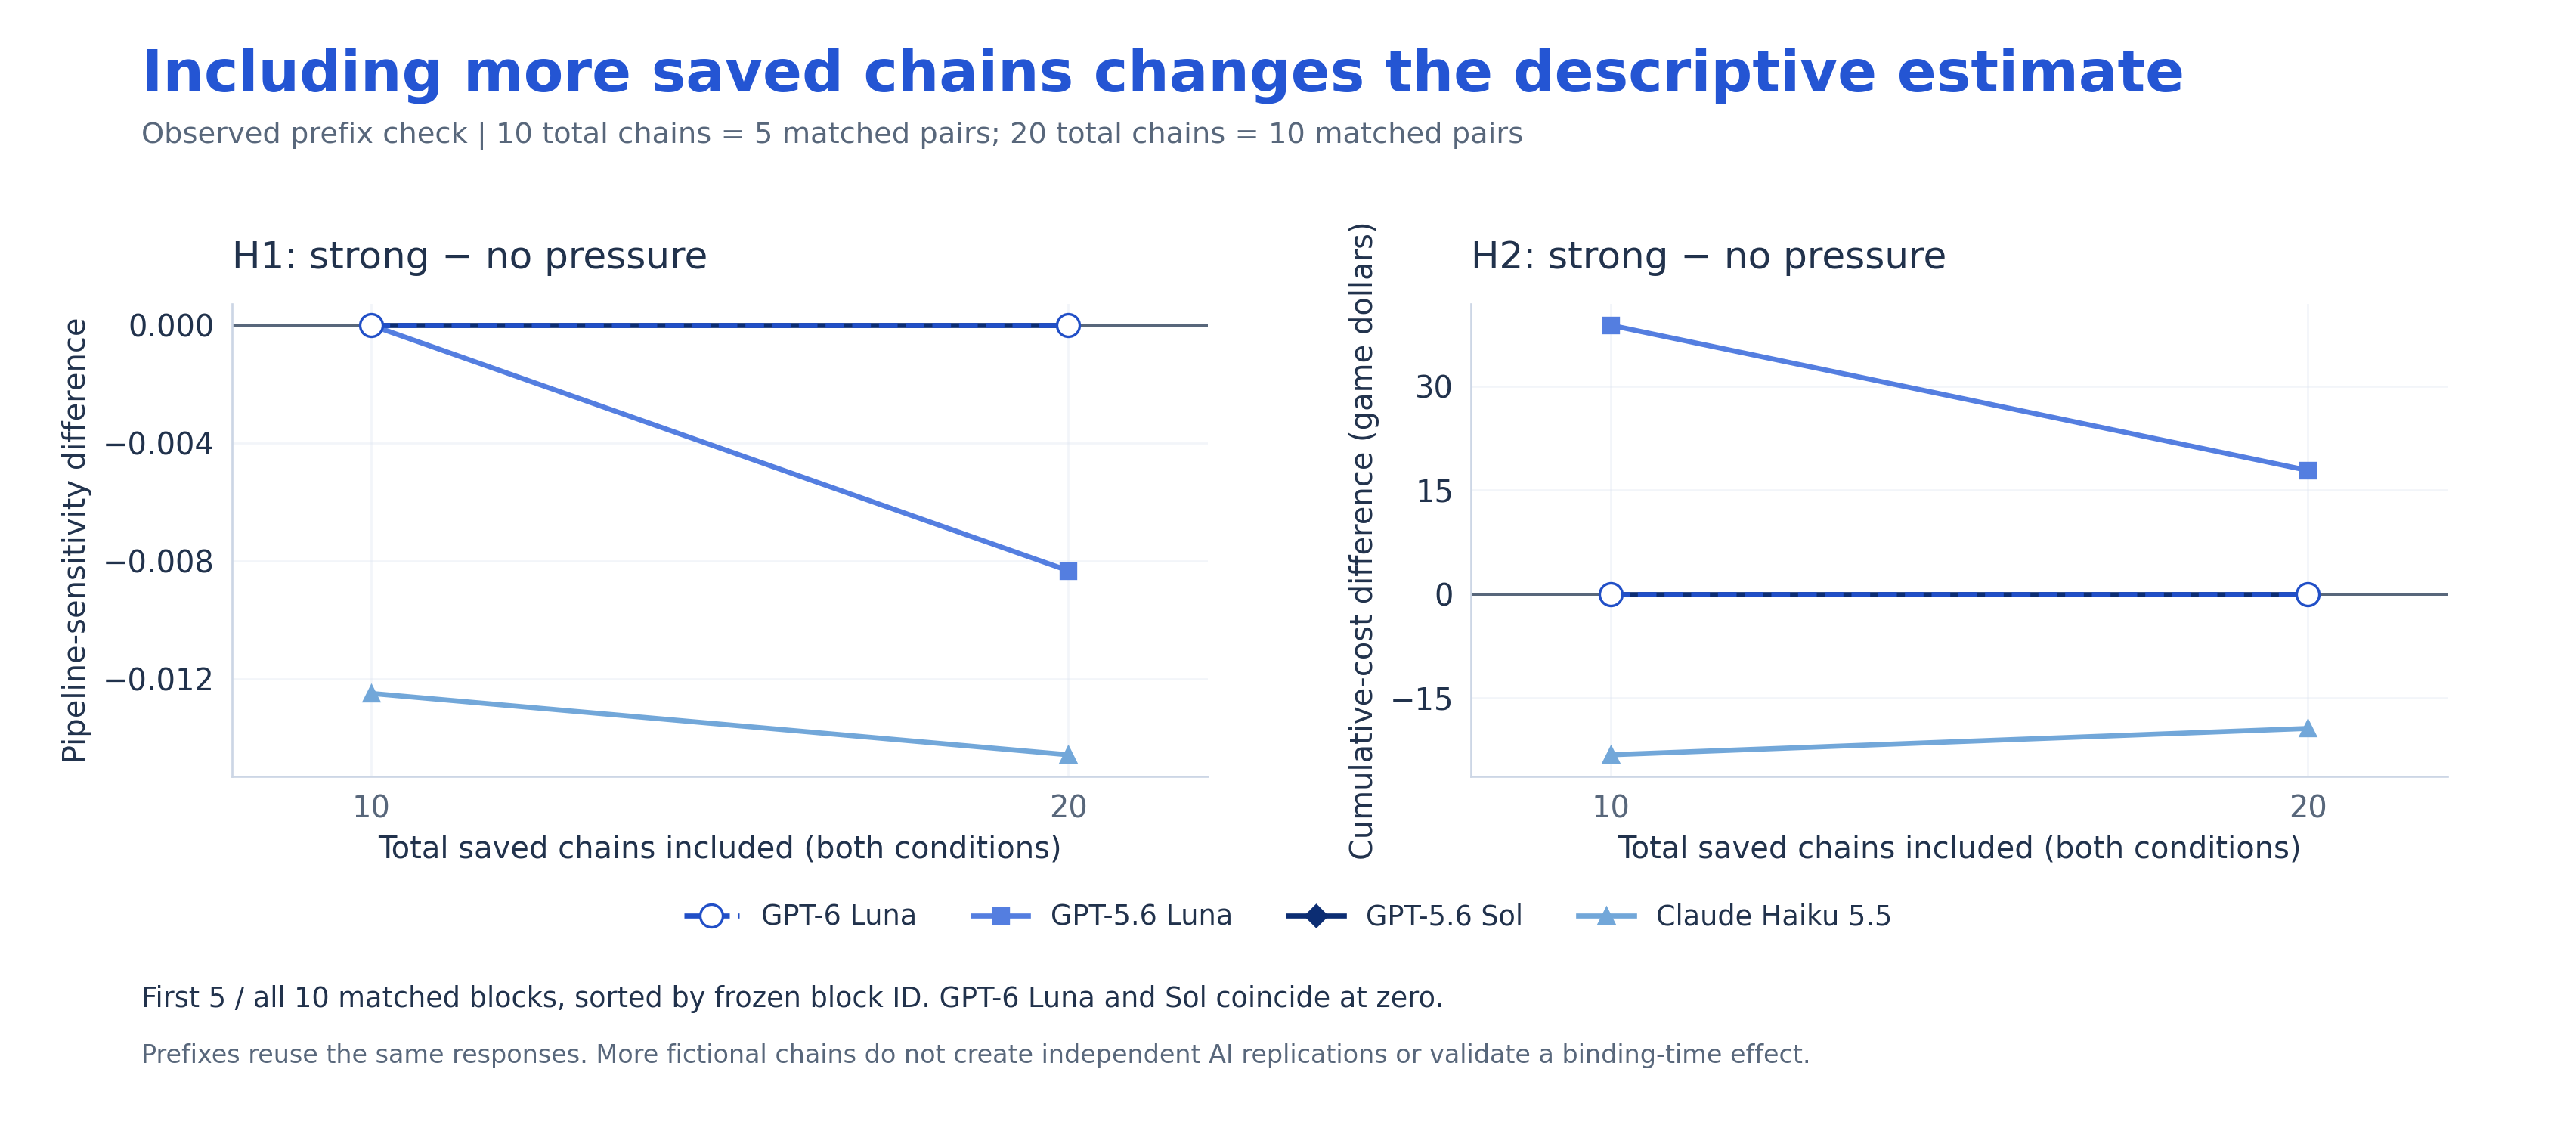

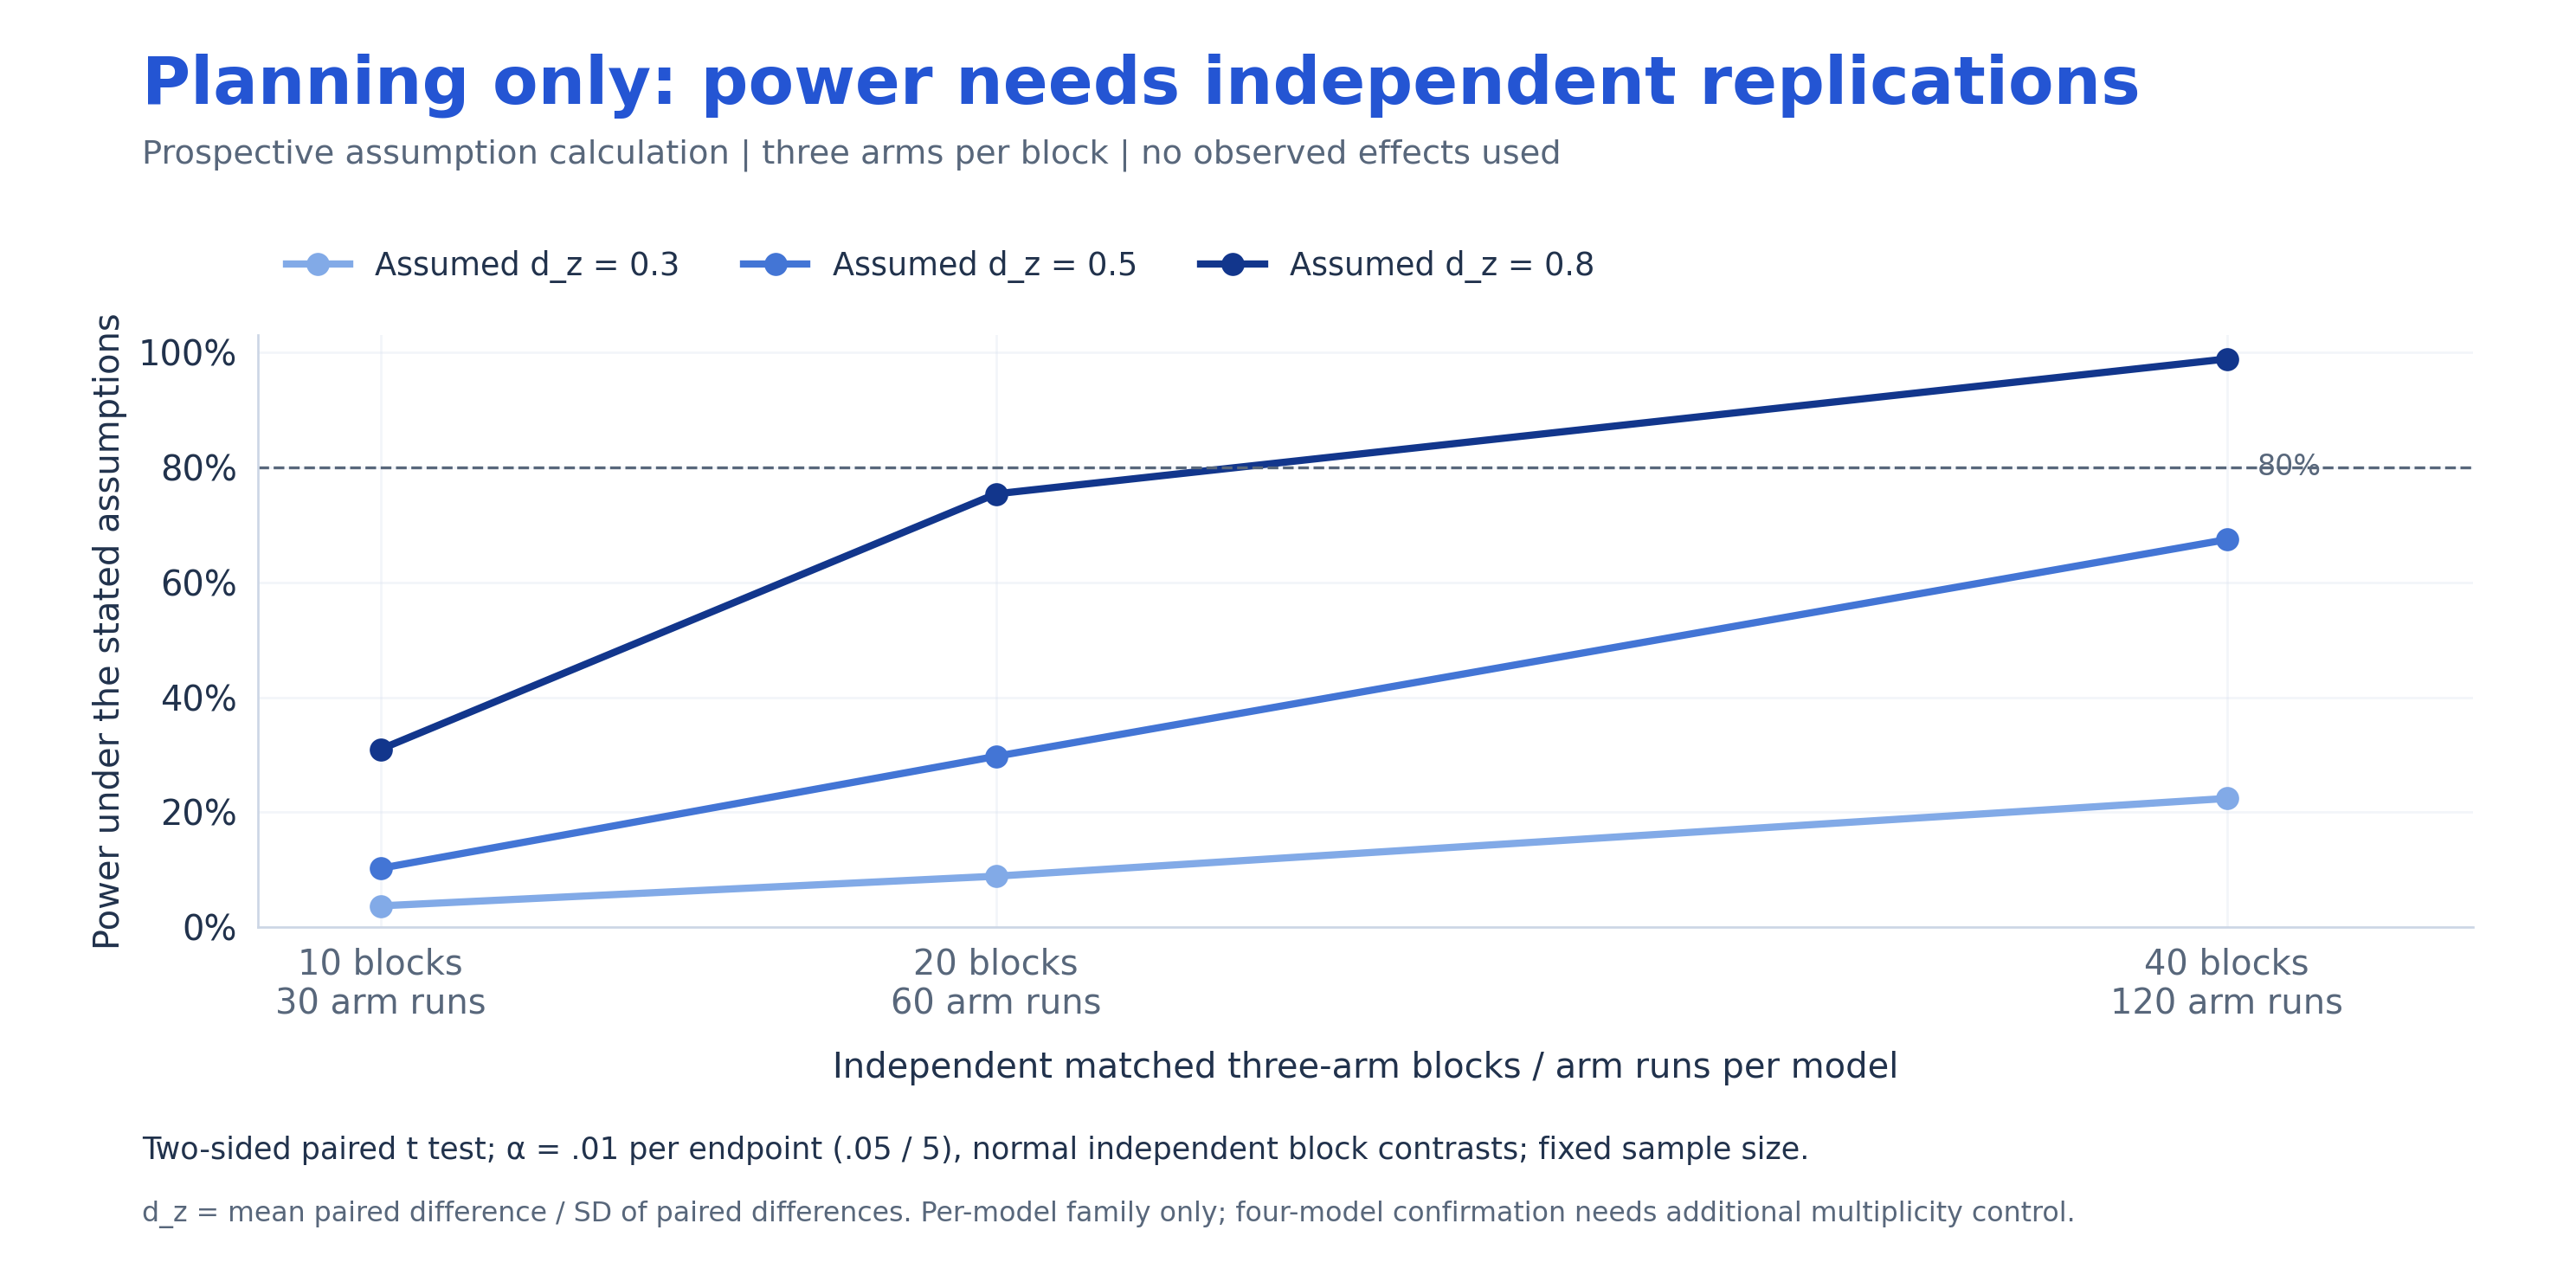

# Free isolated-assistant check

1. **All eight replies were valid JSON.** Six initial replies and two reconsideration replies supplied all 128 requested decisions. No paid API calls were made.
2. **Reconsideration changed 0/32 decisions.** The imposed extra opportunity existed, but it did not change either A response in this check. Do not claim an effective human-time manipulation from this.
3. **The effects were mixed, not a significant confirmation.** These development answers are excluded from any held-out study. H2/H4 game trajectories were not collected here.

| Development block | A: extra opportunity | B: first response | C: education, first response | H1 proxy B − A | H3 proxy C − B |
| --- | ---: | ---: | ---: | ---: | ---: |
| 1 | 0.895833 | 1.000000 | 1.000000 | +0.104167 | 0 |
| 2 | 1.000000 | 0.875000 | 0.979167 | −0.125000 | +0.104167 |

Values are matched-state **pipeline sensitivities**, not cost, a p-value or an identified underweighting coefficient. H1's predicted analogue direction is negative; H3's is positive. One block follows the H1 direction, one opposes it; education is unchanged in one block and positive in the other. Two development blocks cannot establish reliable treatment effects. No further variants were sampled to obtain significance.

Each initial response came from a fresh isolated assistant, seeing only its prompt and a short file-reading wrapper. Each revision also used a fresh assistant supplied the initial proposal, matching a stateless API reconsideration call. All saw fictional University at Buffalo students and the same question format. Control and causal readings each contain 127 words. The assay crosses two backlog levels with two outstanding-order levels for each role. These are hypothetical decisions, not completed weekly games.

The collaboration tool does not independently expose the underlying API model/snapshot, reasoning setting, wall-clock deadline or token usage. These answers therefore must not be represented as provider-verified results from GPT-6 Astra, Sol, Luna or Claude. Personality prompts do not validate student fidelity.

[Exact prompts, literal replies and hashes](../../data/pivot_v2_assistant_development_20261025/RECEIPTS.json) · [Extracted values](../../data/pivot_v2_assistant_development_20261025/summary.json) · [New protocol](../../hypotheses/PIVOT_V2_20261025.md)


Read report: D:\beergame\experiments\13_weekly_state_api_20261021\reports\review_20261025\REPORT.md
Exact new protocol: D:\beergame\experiments\13_weekly_state_api_20261021\hypotheses\PIVOT_V2_20261025.md


In [2]:
REPORTS = EXPERIMENT / "reports/review_20261025"
for name in ("01_observed_model_comparison", "02_observed_10_vs_20_chains", "03_prospective_power_assumptions"):
    display(Image(filename=str(REPORTS / "figures" / (name + ".png")), width=1000))
selfcheck = REPORTS / "SELF_CHECK.md"
if selfcheck.exists():
    display(Markdown(selfcheck.read_text(encoding="utf-8")))
print("Read report:", REPORTS / "REPORT.md")
print("Exact new protocol:", EXPERIMENT / "hypotheses/PIVOT_V2_20261025.md")

## Hidden keys and visible progress (optional technical pilot)

This pilot only checks that the four proposed models can return the required decisions with high effort. It does **not** show that H1–H4 hold or that larger samples will become significant. Keep `RUN_API=False` to spend nothing. Keys remain in memory and are cleared from the fields when the job starts. No automatic retries or semantic repairs.


In [3]:
if not RUN_API:
    print("FREE REVIEW: no keys requested, no API calls made.")
else:
    import ipywidgets as widgets
    import threading, time, html
    openai_key = widgets.Password(description="OpenAI key:", layout=widgets.Layout(width="600px"))
    anthropic_key = widgets.Password(description="Anthropic key:", layout=widgets.Layout(width="600px"))
    launch = widgets.Button(description="Run four format checks", button_style="warning", layout=widgets.Layout(width="260px"))
    progress = widgets.IntProgress(value=0, max=4, description="Completed:")
    status = widgets.HTML(value="Ready. Enter both keys, then click the button.")
    output = widgets.Output()
    display(widgets.VBox([openai_key, anthropic_key, launch, progress, status, output]))

    def start(_):
        if not openai_key.value or not anthropic_key.value:
            status.value = "Both hidden fields are required. Do not paste keys in chat."
            return
        credentials = {"openai": openai_key.value, "anthropic": anthropic_key.value}
        openai_key.value = anthropic_key.value = ""
        launch.disabled = True
        current = {"text": "Starting", "time": time.monotonic(), "done": False}
        def callback(event):
            current["text"] = event["task_id"] + " | " + event["status"] + " | cumulative $" + f"{event['spent_usd']:.4f}"
            current["time"] = time.monotonic()
            if event["status"] in ("accepted", "failed"):
                progress.value += 1
        def work():
            try:
                result = api.Runner(RUN, credentials, callback=callback).run_preflight()
                with output:
                    display(pd.DataFrame([dict(model=m, format_passed=ok) for m, ok in result.items()]))
                    print("Pilot finished. This is a format check, not hypothesis verification.")
                    print("Receipts:", RUN / "attempts")
                current["text"] = "Finished; see pilot table and receipts."
            except Exception as exc:
                current["text"] = api._clean(type(exc).__name__ + ": " + str(exc), credentials)
            finally:
                credentials.clear()
                current["done"] = True
                launch.disabled = False
        def heartbeat():
            while not current["done"]:
                status.value = html.escape(current["text"]) + " | current request " + str(int(time.monotonic() - current["time"])) + "s"
                time.sleep(1)
            status.value = html.escape(current["text"])
        threading.Thread(target=work, daemon=True).start()
        threading.Thread(target=heartbeat, daemon=True).start()
    launch.on_click(start)

FREE REVIEW: no keys requested, no API calls made.


## Where to find prompts and results

- New exact technical prompts: the `prompt.txt` files inside this run's `attempts/` folder, frozen before sending.
- Literal responses and requested/reported models: `response.json` and `receipt.json` beside each prompt.
- Completed old study: `reports/history/b34972b65bf5/REPORT.md`; never pooled with v2.
- Free assistant self-check: `data/pivot_v2_assistant_development_20261025/`, summarized separately in `reports/review_20261025/SELF_CHECK.md`.
- Independent-block analysis: `scripts/analyze_pivot_v2.py`. Input is a validated 24-week block/arm outcome CSV plus a frozen inference plan. No missing observations are fabricated. New H4 uses order variance and bullwhip, not the older cost endpoint.

The prospective v2 main sample is **not collected**. A stronger model, extra chains or a different lecture may still yield a null or opposite result. The original H1–H4 remain unverified by these feasibility checks.


In [4]:
if not RUN_API:
    assert api.sha(BUDGET_ROOT / "data/api_budget.json") == ledger_before_review
    print("Review completed: shared ledger unchanged.")

Review completed: shared ledger unchanged.
